# Discrete PINNs for solving spatio-temporal PDEs



> Note: Using this function requires some small changes in the traditional `jinns` workflow. We provide two examples here on the Fisher KPP equation in 1D and on the Heat equation in 2D.



We comment on those differences in the two following examples.

## Fisher KPP in 1D

The PDE reads

$$
\begin{cases}
\frac{\partial}{\partial t} u(t,x)=D\frac{\partial^2}{\partial x^2} u(t,x) + u(t,x)(r - \gamma u(t,x)), t\geq 0, x\in [0,l]\\
\begin{cases}
u(t,0)=u(t,l)=0,t\geq 0, \text{Dirichlet condition}\\
\frac{\partial u(t,x)}{\partial n}\Big|_{x\in\{0,l\}}=\frac{\partial}{\partial x} u(t,x)\cdot n=0, t\geq0,\text{Neumann condition},
\end{cases}\\
u(0,x)=u_0(x),x\in [0,l]
\end{cases}
$$

$r$, $\gamma$ et $D$ are constant.
For more details on this PDE, see the [Fisher KPP 1D notebook](https://mia_jinns.gitlab.io/jinns/Notebooks/PDE/1D_non_stationary_Fisher_KPP_Bounded_Domain/).

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
import jax

jax.config.update("jax_enable_x64", True)

In [3]:
from jax import random, vmap
import jax.numpy as jnp
import equinox as eqx
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams["font.size"] = 17


key = random.PRNGKey(2)

In [4]:
import jinns

In [5]:
# Here we define the model parameters that will remain fixed in all the problem
D = 1.0
r = 3.0
g = 3.0

We now define the time discretization for solving the EDO on the parameters (see more details [here](https://mia_jinns.gitlab.io/jinns/api/solve/solve_neural_galerkin/)). Finer resolution will lead to more accurate solutions but will be more expensive to compute.

`tmin` and `tmax` here define the time interval on which we want to solve the PDE.

In [6]:
tmin = 0.0
tmax = 5.0
dt = 0.005
times = jnp.arange(tmin, tmax + dt, dt)
print(len(times), times)

1001 [0.    0.005 0.01  ... 4.99  4.995 5.   ]


As mentioned in the introduction, the boundary condition must be hardcoded. There exists in the PINN literature several approaches. Here we implement the two most common approach for Neumann and Dirichlet boundary conditions.

- We implement **fourier frequency embedding** (https://arxiv.org/pdf/2504.01093v1) as an `input_transform` in order to hard constraint Neumann BC.
- Implementation of hard constraint for Dirichlet BC is much more straightforward using an `output_transform`.

In [7]:
def input_transform(x, params):
    """
    x is the PINN input
    this is for Neumann
    """
    return jnp.array([jnp.cos(jnp.pi * (x[0] - xmin) / (xmax - xmin))])


def output_transform(x, pinn_out, params):
    """
    this is for Dirichlet
    """
    return (x[0] - xmin) * (x[0] - xmax) * pinn_out

Next we define the PINN. As we said, a **stationary PINN** must be instanciated $u_\nu(x)$. Dependency on time if through the flow of $\nu(t)$.

In [8]:
eqx_list = (
    (eqx.nn.Linear, 1, 16),
    (jax.nn.tanh,),
    (eqx.nn.Linear, 16, 16),
    (jax.nn.tanh,),
    (eqx.nn.Linear, 16, 1),
)
key, subkey = random.split(key)
u_pinn, init_nn_params_pinn = jinns.nn.PINN_MLP.create(
    key=subkey,
    eqx_list=eqx_list,
    eq_type="PDEStatio",
    output_transform=output_transform,  # for Dirichlet BC
    # input_transform=input_transform # for Neumann BC
)
init_params_pinn = jinns.parameters.Params(
    nn_params=init_nn_params_pinn,
    eq_params={
        "D": jnp.array([D]),
        "r": jnp.array([r]),
        "g": jnp.array([g]),
    },
)

Next we define the DataGenerator. The DataGenerator also only implements the space domain, as is we were solving a stationary problem.

In [9]:
n = 1024
batch_size = None
dim = 1
xmin = -1
xmax = 1
method = "uniform"

key, subkey = random.split(key)
train_data = jinns.data.CubicMeshPDEStatio(
    key=subkey,
    n=n,
    omega_batch_size=batch_size,
    dim=dim,
    min_pts=(xmin,),
    max_pts=(xmax,),
    method=method,
)

Next we define the initial condition that will be fit first to get the initial set of parameters.

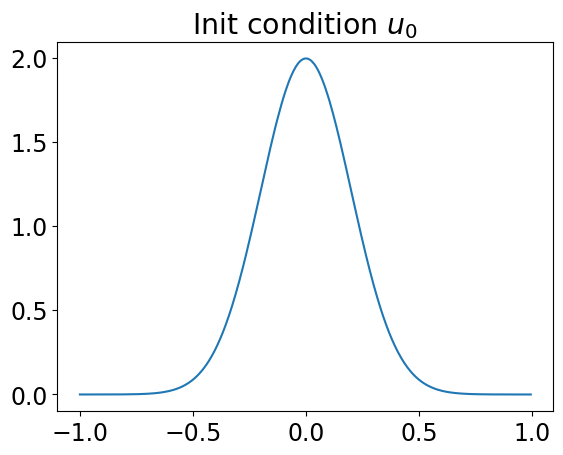

In [10]:
from jax.scipy.stats import norm

# Initial condition N(0,1)
sigma_init = 0.2 * jnp.ones((1))
mu_init = 0 * jnp.ones((1))


def u0(x):
    return jnp.squeeze(norm.pdf(x, loc=mu_init, scale=sigma_init))


plt.plot(
    train_data.omega.sort(axis=0),
    vmap(u0, (0), 0)(train_data.omega.sort(axis=0)),
)
plt.title(r"Init condition $u_0$")
plt.show()

Next we defined the dynamic loss without the time component, as if in the stationary case.

In [11]:
class FisherKPP_statio(jinns.loss.PDEStatio):
    """
    This implements the RHS of the equation of the top of the notebook
    """

    def equation(self, x, u, params):
        r"""
        Evaluate the dynamic loss at $x$.

        Parameters
        ---------
        x
            A jnp array a point in $\Omega$
        u
            The PINN
        params
            The dictionary of parameters of the model.
            Typically, it is a dictionary of
            dictionaries: `eq_params` and `nn_params`, respectively the
            differential equation parameters and the neural network parameter
        """
        lap = jinns.loss.laplacian_rev(x, u, params)[..., None]

        return -(
            params.eq_params.D * lap
            + u(x, params) * (params.eq_params.r - params.eq_params.g * u(x, params))
        )


fisher_dynamic_loss = FisherKPP_statio()

Accordingly, the main loss object is a `LossPDEStatio`.

In [12]:
loss_pinn = jinns.loss.LossPDEStatio(
    u=u_pinn,
    dynamic_loss=fisher_dynamic_loss,
    params=init_params_pinn,
)

/home/hugo/Documents/recherche/pinn/gitlab/jinns/loss/_LossPDE.py:128: UserWarning: Missing boundary condition.
  warnings.warn("Missing boundary condition.")


We define the time slices (elements of `times`) at which we want to save the parameters for subsequent PINN evaluations.

In [13]:
times_saved = [
    0.0,
    0.1,
    1.0,
    4.0,
    5.0,
]  # the results will returns the Params \nu(t) for these times

The first training step consists in fitting the initial condition. The user must define the optimizer and the number of iterations for this step. **It is crucial that the initial condition be well fitted by the neural network** or errors will rapidly propagate in the parameter updates of the Discrete PINN scheme.

On this simple 1D problem, 10000 Adam steps are enough though.

In [14]:
import optax

n_iter_ic = 10000
optimizer_ic = optax.adam(1e-3)

n_iter = 5  # this might be even too much for this simple problem
optimizer = jinns.optimizers.vanilla_ngd()

Now we are set for the call to `jinns.solve_discrete_pinn` !

In [15]:
_, _, _, params_saved, total_loss_list = jinns.solve_discrete_pinn(
    times=times,
    times_saved=times_saved,
    init_params=init_params_pinn,
    data=train_data,
    loss=loss_pinn,
    n_iter=n_iter,
    optimizer=optimizer,
    initial_condition_fun=u0,
    n_iter_ic=n_iter_ic,
    optimizer_ic=optimizer_ic,
    print_loss_every=len(times) // 10,
    scheme="rk1",
)

Initialization time: 6.9141387939453125e-06


 #-- Fitting the initial condition for t0= 0.0
Initialization time: 0.15813565254211426

Compilation took
 0.5062165260314941 

[train] Iteration 0: loss value = 0.4882771079916374
[train] Iteration 1000: loss value = 0.00019239608756012674
[train] Iteration 2000: loss value = 7.578979366640021e-05
[train] Iteration 3000: loss value = 3.185067008047145e-05
[train] Iteration 4000: loss value = 1.1808392095428065e-05
[train] Iteration 5000: loss value = 2.995168366486086e-06
[train] Iteration 6000: loss value = 8.56351480706428e-07
[train] Iteration 7000: loss value = 4.947014306554095e-07
[train] Iteration 8000: loss value = 3.2045336000306123e-07
[train] Iteration 9000: loss value = 2.243471569299989e-07

Stopping main optimization loop, cause: max iteration is reached

Training took
 5.324342966079712 


Final iteration 10000: train loss value = 1.7687343831436765e-07


 #-- Starting the optimizations at each time step.
[Train Discrete PIN

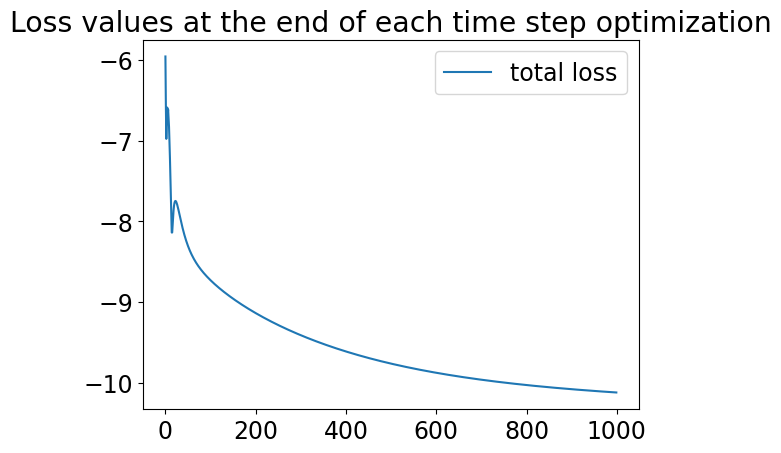

In [16]:
plt.plot(jnp.log10(total_loss_list[n_iter - 1 :: n_iter]), label="total loss")
plt.legend()
plt.title("Loss values at the end of each time step optimization")
plt.show();

We set up a plotting function for plotting the PINN at each time step for which we have saved the parameters

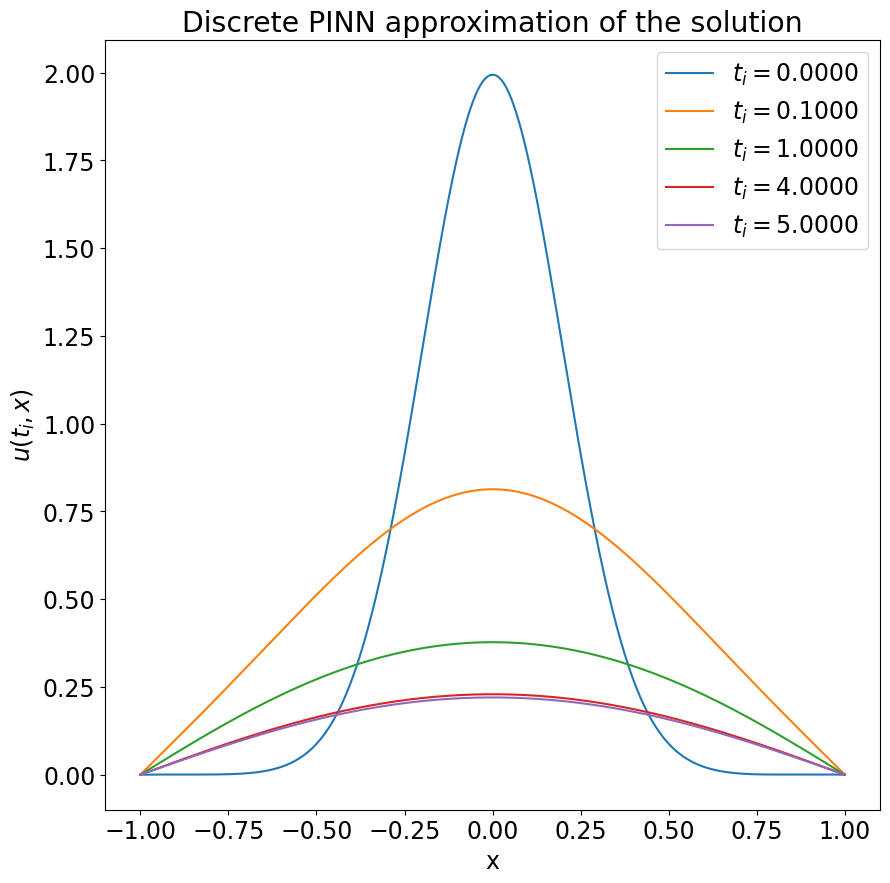

In [17]:
from functools import partial

u_est_pinn_at_times = [
    partial(u_pinn, params=p) for p in params_saved
]  # Note cannot use lambda here (classical mistake)

nx = 500
val_xdata = jnp.linspace(xmin, xmax, nx)

jinns.plot.plot1d_slice_time_discrete(
    u_est_pinn_at_times,
    xdata=val_xdata,
    time_slices=times_saved,
    figsize=(10, 10),
    title="Discrete PINN approximation of the solution",
)
plt.show()

You can compare the result of the classical optimization made in the [Fisher KPP 1D notebook](https://mia_jinns.gitlab.io/jinns/Notebooks/PDE/1D_non_stationary_Fisher_KPP_Bounded_Domain/). On this simple example, both approaches compare similarly.

Since we skip to a totally different problem, and thus different equation parameters, we must reinitialise the metaclass used for `EqParams`. This is for jinns internal reason, just run the following command.

In [18]:
from jinns.parameters import EqParams

EqParams.clear()

## Heat equation in 2D

The PDE reads


$$
\begin{cases}
\partial_t u(t,x,y)-D \Delta u(t,x,y) = 0,\\
u(0, x, y)=\sin(\pi x)\sin(\pi y), \textrm{ (IC)}\\
u(t, x, y)= 0, \; x \in \partial \Omega \textrm{ (Dirichlet BC)} \\
\end{cases}
$$
with $I \times \Omega=[0, 1] \times [-1,1]^2$.

With this particular periodic initial condition, the solution is simply an exponential decay of $u_0$ with time 
$$u^\star(t,x, y) = e^{-2D\pi^2 t}\sin(\pi x)\sin(\pi y).$$

This section will strictly follow the same logic as the previous one.

Define the problem parameter

In [19]:
D = 0.25

Define the initial condition and the true solution

In [20]:
def u0(x):
    res = jnp.sin(jnp.pi * x[0]) * jnp.sin(jnp.pi * x[1])
    return res


def u_true(t_x):
    t, x = t_x[0], t_x[1:]
    return jnp.exp(-2 * D * t * jnp.pi**2) * u0(x)

Define the time discretization of the Discrete PINN approach

In [21]:
tmin = 0.0
tmax = 1.0
dt = 0.005  # the time discretization used by the ODE solver, can be subject to instability if too big
times = jnp.arange(tmin, tmax + dt, dt)

Define the stationary 2D DataGenerator

In [22]:
key, subkey = random.split(key)
n = 1024
ni = 1024
dim = 2
xmin, xmax = -1, 1
ymin, ymax = -1, 1
train_data = jinns.data.CubicMeshPDEStatio(
    key=subkey,
    n=n,
    dim=dim,
    min_pts=(xmin, ymin),
    max_pts=(xmax, ymax),
    method="uniform",
)

Instanciate the stationary PINN with hardcoded Dirichlet BC

In [23]:
input_dim = 1 + 1
output_dim = 1
hidden_size = 16

eqx_list = (
    (eqx.nn.Linear, input_dim, hidden_size),
    (jax.nn.tanh,),
    (eqx.nn.Linear, hidden_size, hidden_size),
    (jax.nn.tanh,),
    (eqx.nn.Linear, hidden_size, output_dim),
)


def output_transform(x, pinn_out, params):
    """
    this is for Dirichlet
    """
    return (x[0] - xmin) * (x[0] - xmax) * (x[1] - ymin) * (x[1] - ymax) * pinn_out


key, subkey = random.split(key)
u, init_nn_params = jinns.nn.PINN_MLP.create(
    key=subkey,
    eqx_list=eqx_list,
    eq_type="PDEStatio",
    output_transform=output_transform,
)
init_params = jinns.parameters.Params(
    nn_params=init_nn_params,
    eq_params={"D": D},
)

Define the dynamic loss as if in the stationary case

In [24]:
class HeatEquationStatio(jinns.loss.PDEStatio):
    def equation(self, x, u, params):
        # lap = jinns.loss.laplacian_rev(x, u, params, eq_type="PDEStatio")
        u_ = lambda x: u(x, params).squeeze()
        lap = jnp.sum(jnp.diag(jax.hessian(u_)(x)))
        D = params.eq_params.D

        res = -D * lap
        return res[None]


dyn_loss_heat = HeatEquationStatio()

In [25]:
loss = jinns.loss.LossPDEStatio(
    u=u,
    dynamic_loss=dyn_loss_heat,
    params=init_params,
)

/home/hugo/Documents/recherche/pinn/gitlab/jinns/loss/_LossPDE.py:128: UserWarning: Missing boundary condition.
  warnings.warn("Missing boundary condition.")


Define the time steps at which the parameters must be saved and start the training with Discrete PINN approach

In [26]:
times_saved = [0.0, 0.05, 0.1, 0.99]
n_iter_ic = 10000
optimizer_ic = optax.adam(1e-3)

n_iter = 5
optimizer = jinns.optimizers.vanilla_ngd()

In [27]:
_, _, _, params_saved, total_loss_list = jinns.solve_discrete_pinn(
    times=times,
    times_saved=times_saved,
    init_params=init_params,
    data=train_data,
    loss=loss,
    n_iter=n_iter,
    optimizer=optimizer,
    initial_condition_fun=u0,
    n_iter_ic=n_iter_ic,
    optimizer_ic=optimizer_ic,
    print_loss_every=len(times) // 10,
    scheme="rk1",
)

Initialization time: 7.867813110351562e-06


 #-- Fitting the initial condition for t0= 0.0
Initialization time: 0.041661739349365234

Compilation took
 0.521479606628418 

[train] Iteration 0: loss value = 0.24431821412195878
[train] Iteration 1000: loss value = 8.631668460707163e-05
[train] Iteration 2000: loss value = 5.0564801721731916e-05
[train] Iteration 3000: loss value = 3.506767953657352e-05
[train] Iteration 4000: loss value = 2.4263740159208322e-05
[train] Iteration 5000: loss value = 1.571101223061862e-05
[train] Iteration 6000: loss value = 1.149230012984511e-05
[train] Iteration 7000: loss value = 7.91280022069885e-06
[train] Iteration 8000: loss value = 6.355353427997668e-06
[train] Iteration 9000: loss value = 5.619039735371734e-06

Stopping main optimization loop, cause: max iteration is reached

Training took
 7.254565238952637 


Final iteration 10000: train loss value = 5.080222459052504e-06


 #-- Starting the optimizations at each time step.
[Train Discrete PINN]

We must extend the 1D plotting function to handle the 2D case.


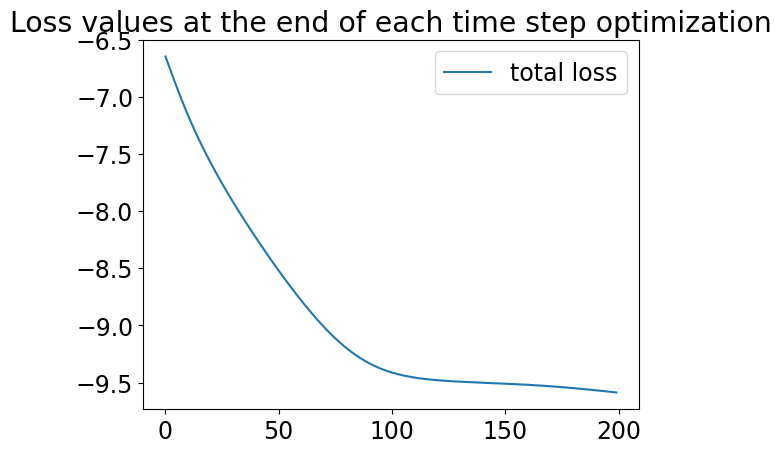

In [28]:
plt.plot(jnp.log10(total_loss_list[n_iter - 1 :: n_iter]), label="total loss")
plt.legend()
plt.title("Loss values at the end of each time step optimization")
plt.show();

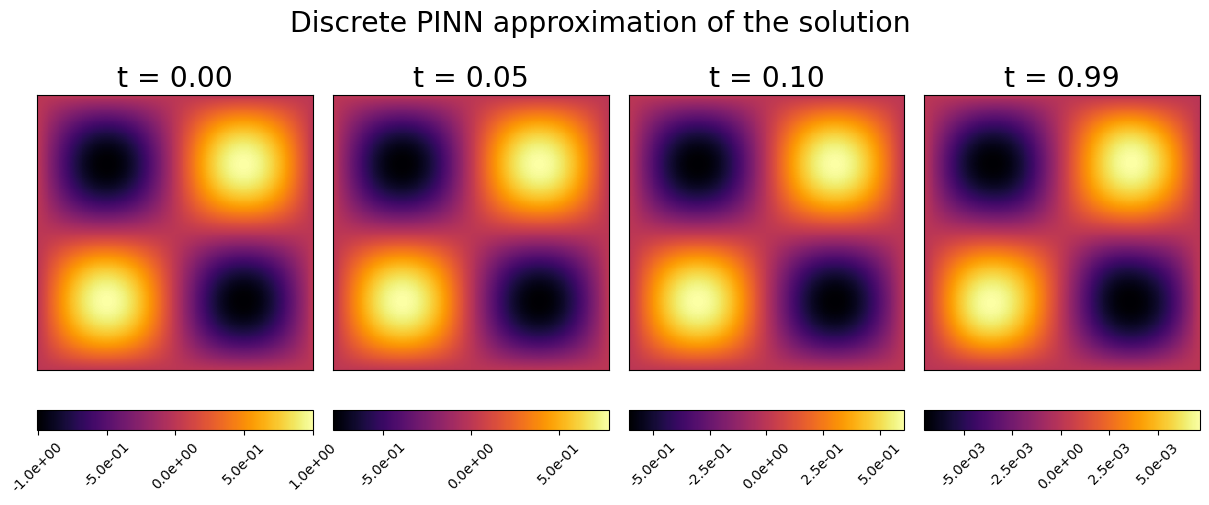

In [29]:
u_est_pinn_at_times = [
    partial(u, params=p) for p in params_saved
]  # Warning: you cannot use `lambda`` here (classical mistake)

nx = ny = 300
val_xydata = (jnp.linspace(xmin, xmax, nx), jnp.linspace(ymin, ymax, ny))

jinns.plot.plot2d_slice_time_discrete(
    u_est_pinn_at_times,
    xydata=val_xydata,
    time_slices=times_saved,
    figsize=(15, 5),
    title="Discrete PINN approximation of the solution",
)
plt.show()

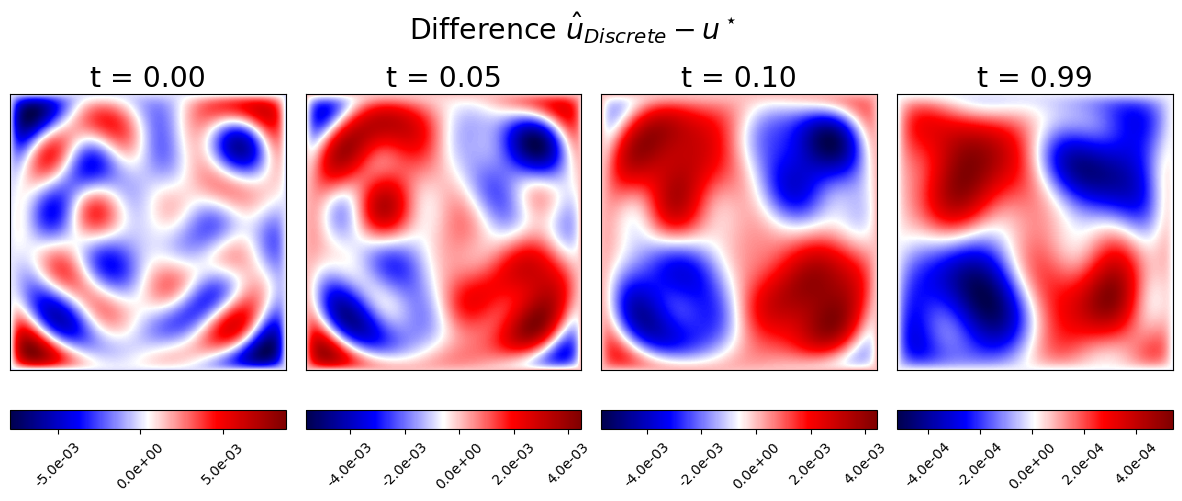

In [30]:
u_true_t = lambda t, xy: u_true(jnp.concatenate([jnp.array([t]), xy], axis=-1))

diff_at_times = [
    partial(lambda xy, params, t: u(xy, params) - u_true_t(t, xy), params=p, t=t)
    for (p, t) in zip(params_saved, times_saved)
]

jinns.plot.plot2d_slice_time_discrete(
    diff_at_times,
    xydata=val_xydata,
    time_slices=times_saved,
    figsize=(15, 5),
    title=r"Difference $\hat{u}_{Discrete} - u^\star$",
    cmap="seismic",
)
plt.show()